# Portable：検索せず、JSONから同じ公園を開く

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/u-kitazawa/rhinestone/blob/develop/showcase/03_portable_vector.ipynb)

```python
plan = AccessPlan.from_dict(json.loads(Path("vector-plan.json").read_text()))
frame = receiving_app.open(plan, "pyogrio", runtime=pyogrio)
```

[02](02_open_vector.ipynb)で作成した **vector-plan.json** を、このNotebookの作業ディレクトリへアップロードしてから実行します。
別Notebook・新しいkernelで実行でき、検索結果や変数resourceは不要です。
**検索APIへの再問い合わせはありませんが、データ配布URLへの通信は発生します。**
受信側は既知の配布URLだけを許可します。信頼できないJSONのURIをそのまま許可リストへ追加しません。

出典：那須塩原市 建設部 保全管理課「公園 都市整備施設」（【那須塩原市】公園 都市整備）。
[元リソース](https://opendata-nasu.opendatastack.jp/dataset/shisetu-kouenn-tosisetibi/resource/d94a1299-e0fb-4c9a-9a9f-aac7dcb97763) · [配布データ](https://nasu-ckan.s3.amazonaws.com/ckan/resources/d94a1299-e0fb-4c9a-9a9f-aac7dcb97763/011201.json) · [CC BY 2.1 JP](https://creativecommons.org/licenses/by/2.1/jp/) · [利用規約](https://opendata-nasu.opendatastack.jp/pages/userpolicy)。
名称・位置を抽出し、表示用にEPSG:4326へ変換しています。写真・リンク先画像は取得しません。
2026-10-20確認、提供元の最終更新表示は2016-04-04。最新の公園一覧・営業状況ではありません。


In [1]:
import os
import subprocess
import sys

# 固定コミット。保守者のlocal smokeだけは、検証対象checkoutを明示して使用します。
if os.environ.get("RHINESTONE_SHOWCASE_LOCAL") != "1":
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "rhinestone @ git+https://github.com/u-kitazawa/rhinestone.git@9bae025b08357d23e5f5339c25a777a1445da176",
            "pyogrio==0.13.0",
            "geopandas==1.1.1",
            "matplotlib==3.10.7",
        ]
    )
else:
    print("Local smoke: explicit checkout and caller-owned dependencies")

Local smoke: explicit checkout and caller-owned dependencies


In [2]:
import json
from pathlib import Path

from rhinestone import AccessPlan, Catalog, Provider, configure

input_path = Path("vector-plan.json")
if not input_path.is_file():
    raise ValueError("02で作ったvector-plan.jsonをアップロードしてください。")
if input_path.stat().st_size > 65536:
    raise ValueError("想定より大きなPlanです。入力ファイルを確認してください。")
received_plan = AccessPlan.from_dict(json.loads(input_path.read_text(encoding="utf-8")))
TRUSTED_URI = "https://nasu-ckan.s3.amazonaws.com/ckan/resources/d94a1299-e0fb-4c9a-9a9f-aac7dcb97763/011201.json"
if received_plan.uri != TRUSTED_URI or received_plan.format != "geojson":
    raise ValueError(
        "この受信例が許可する公園GeoJSONではありません。Planと出典を確認してください。"
    )
receiving_app = configure(
    catalog=Catalog(
        (
            Provider(
                "permitted-vector", "direct", {"uri": TRUSTED_URI, "format": "geojson"}
            ),
        )
    )
)

In [3]:
import pyogrio

from rhinestone.errors import ResourceAccessError

frame = None
try:
    frame = receiving_app.open(received_plan, "pyogrio", runtime=pyogrio)
except ResourceAccessError:
    print(
        "Open失敗：配布URL・権限・Runtimeのdriverを確認してください。検索し直さず原因を確認できます。"
    )
    raise
print("Features:", len(frame), "CRS:", frame.crs)
print("Search Provider: not configured")

Features: 10 CRS: EPSG:4979
Search Provider: not configured


   黒磯公園
那珂川河畔公園
鳥野目河川公園
 東那須野公園
  烏ヶ森公園
   乃木公園
   大山公園
 八汐第一公園
 八汐第二公園
   今井公園


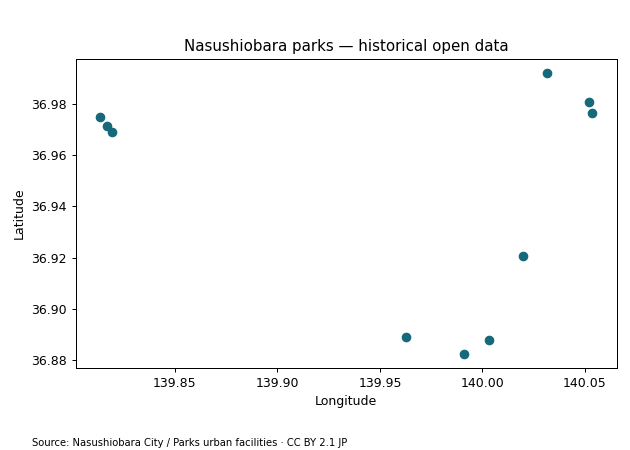

In [4]:
import matplotlib.pyplot as plt

if frame.empty or frame.crs is None or "名称" not in frame.columns:
    raise ValueError("この表示例には名称・geometry・CRSのある非空データが必要です。")
view = frame[["名称", "geometry"]].to_crs(epsg=4326)
ax = view.plot(figsize=(7, 5), color="#16697a", markersize=45)
ax.set(
    title="Nasushiobara parks — historical open data",
    xlabel="Longitude",
    ylabel="Latitude",
)
ax.figure.text(
    0.05,
    0.01,
    "Source: Nasushiobara City / Parks urban facilities · CC BY 2.1 JP",
    fontsize=8,
)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()
print(view["名称"].to_string(index=False))

## 自分の用途へ

02の条件を変えて別のデータを選ぶ場合は、受信側でも配布元・ライセンス・容量を検証し、信頼済み宛先を明示的に構成してください。
AccessPlanはデータ本体のsnapshotではありません。同じJSONでも外部ファイルが更新されれば結果は変わります。
JSONの構文/契約不正は隠さず停止します。出典・ライセンスはPlanを渡す場合も引き継いでください。
